In [1]:
# Standard imports for signal processing
import numpy as np                    # Numerical operations
import matplotlib.pyplot as plt       # Plotting
from scipy import signal              # Signal processing
from scipy.fft import fft, fftshift   # Fourier transforms

# Display settings for better plots
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

In [2]:
# Basic arithmetic
a = 5
b = 3
sum_val = a + b        # Addition
difference = a - b     # Subtraction
product = a * b        # Multiplication
quotient = a / b       # Division
power = a**2           # Exponentiation

print(f"Sum: {sum_val}")
print(f"Power: {power}")

# Multiple assignment
x, y, z = 1, 2, 3

Sum: 8
Power: 25


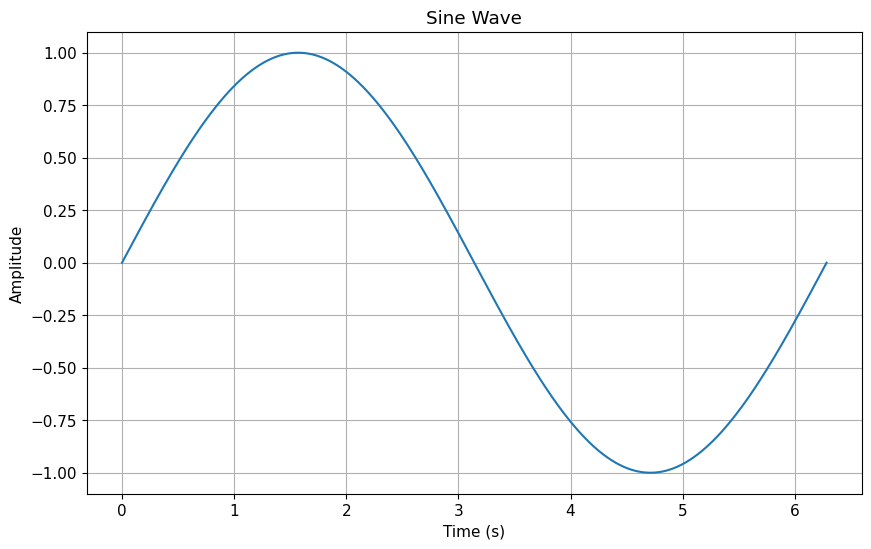

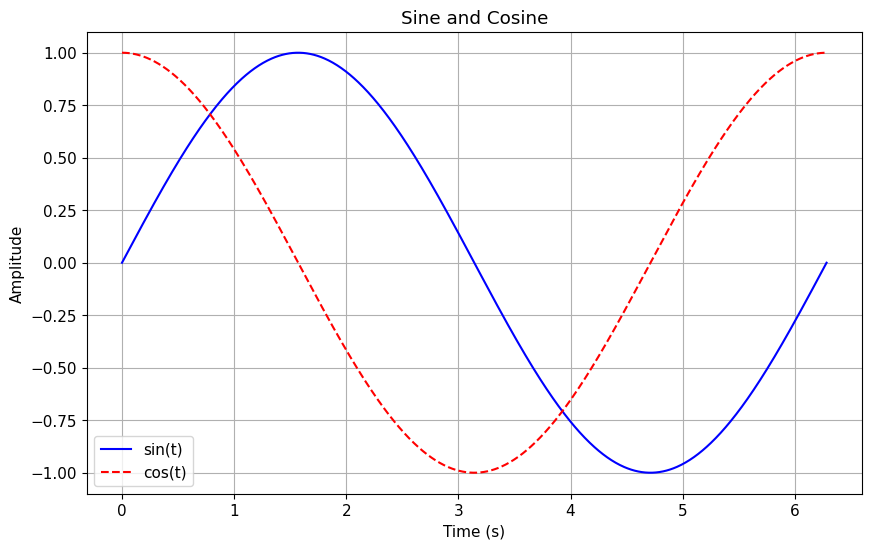

In [3]:
# Simple plot
t = np.linspace(0, 2*np.pi, 1000)
y = np.sin(t)

plt.figure()
plt.plot(t, y)
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.title('Sine Wave')
plt.grid(True)
plt.show()

# Multiple plots on same figure
y1 = np.sin(t)
y2 = np.cos(t)

plt.figure()
plt.plot(t, y1, 'b-', label='sin(t)')
plt.plot(t, y2, 'r--', label='cos(t)')
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.title('Sine and Cosine')
plt.legend()
plt.grid(True)
plt.show()

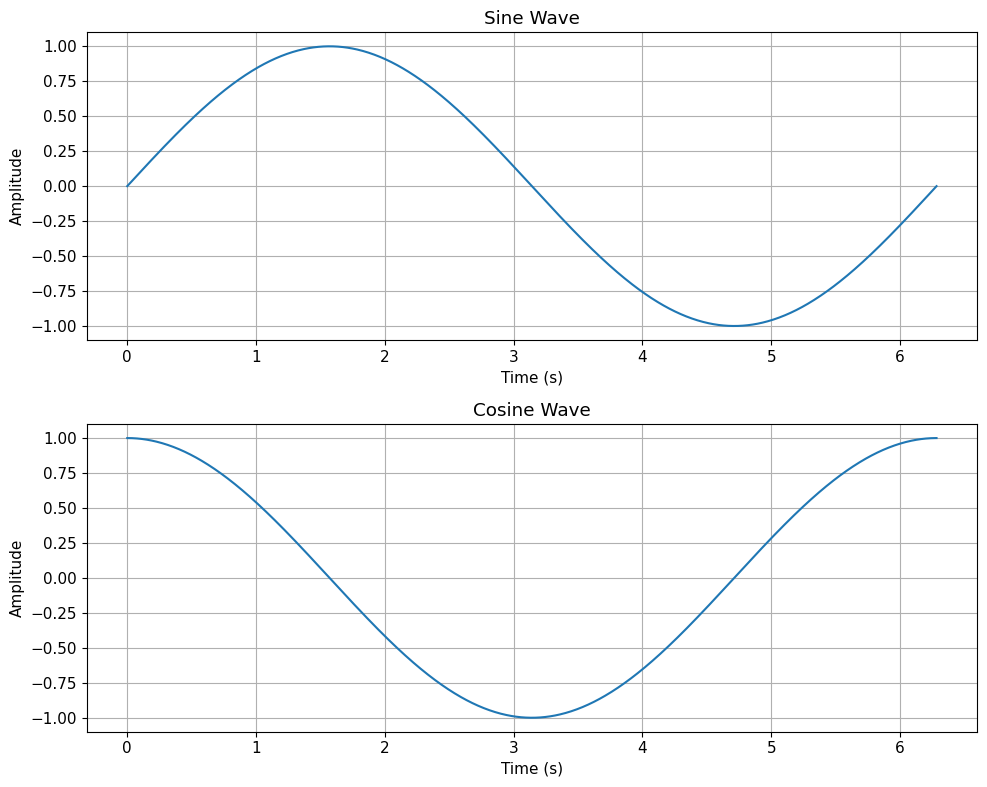

In [4]:
# Create multiple plots in one figure
t = np.linspace(0, 2*np.pi, 1000)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8))

ax1.plot(t, np.sin(t))
ax1.set_title('Sine Wave')
ax1.set_xlabel('Time (s)')
ax1.set_ylabel('Amplitude')
ax1.grid(True)

ax2.plot(t, np.cos(t))
ax2.set_title('Cosine Wave')
ax2.set_xlabel('Time (s)')
ax2.set_ylabel('Amplitude')
ax2.grid(True)

plt.tight_layout()
plt.show()

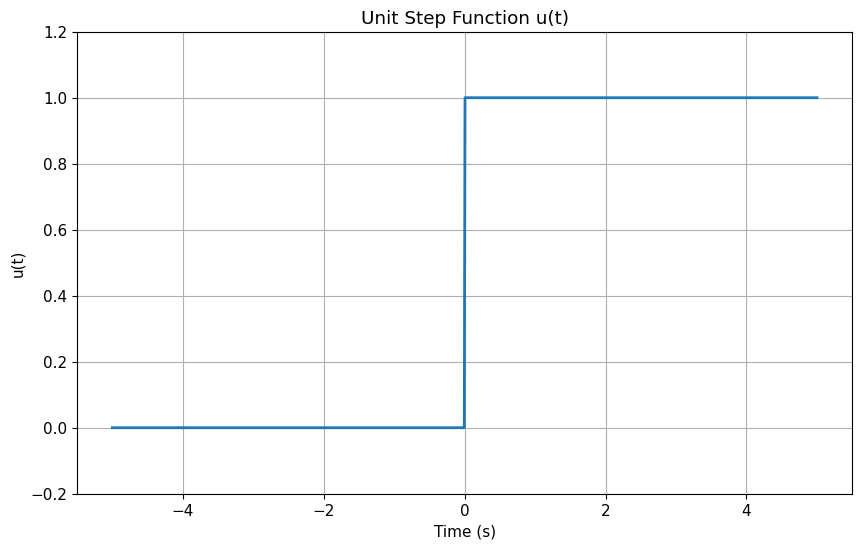

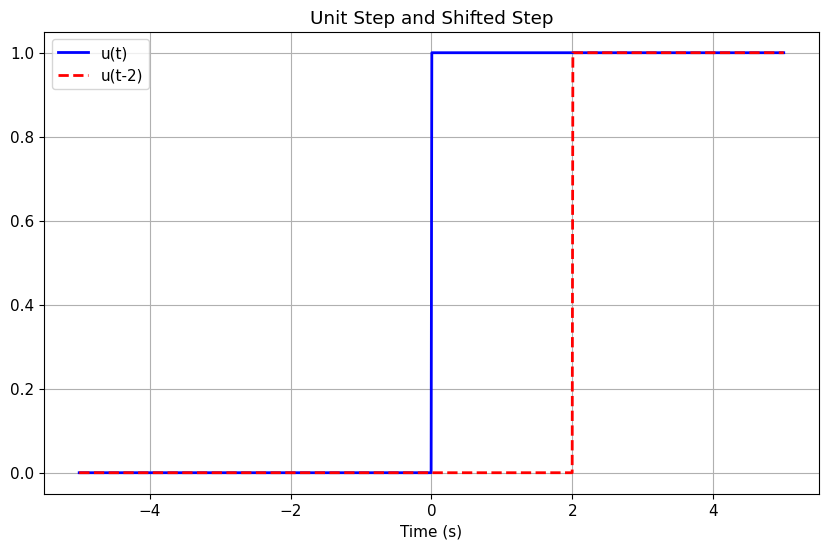

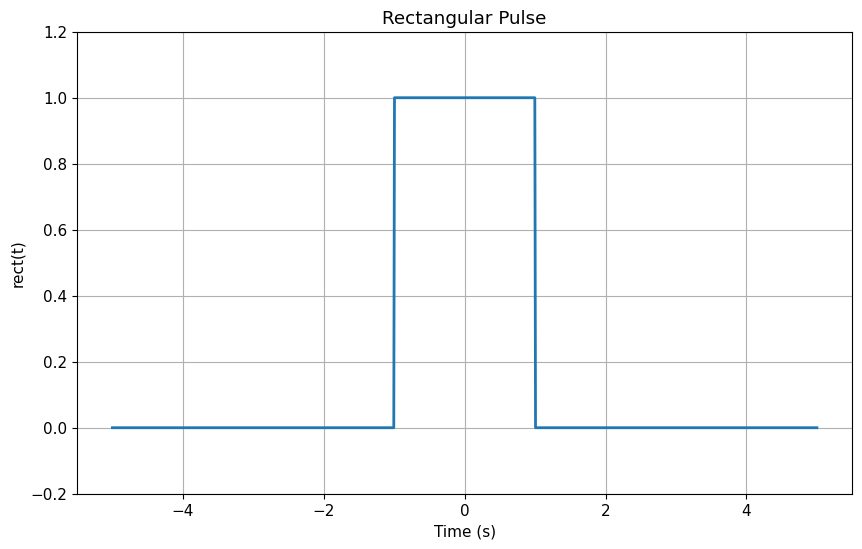

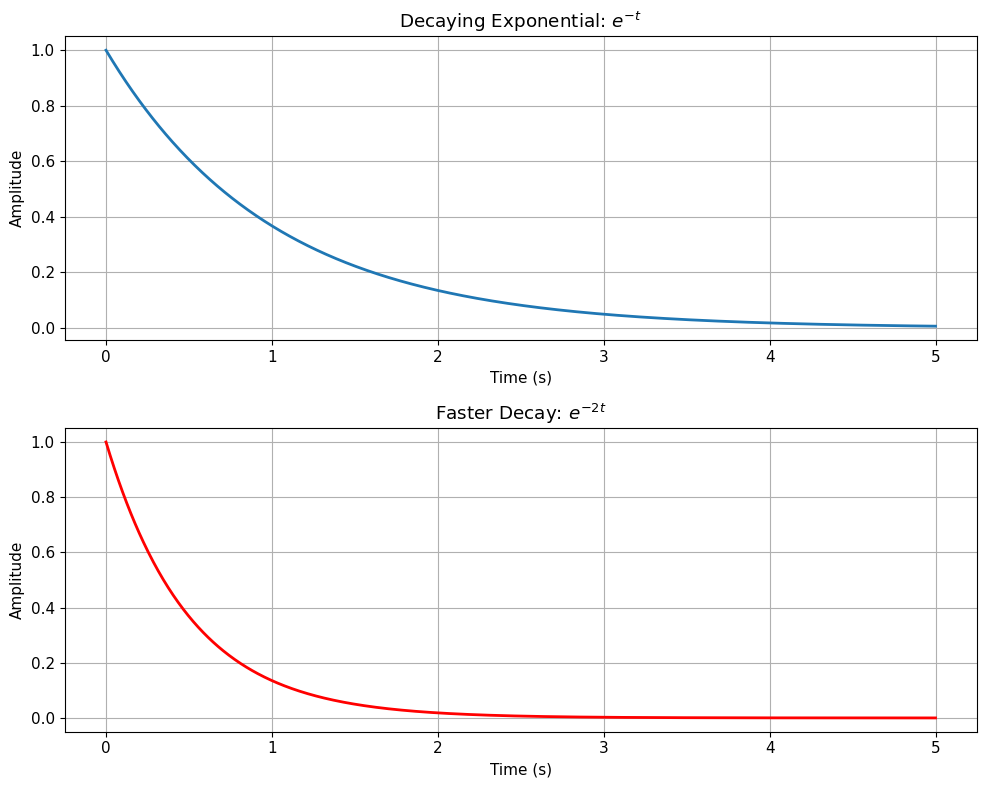

In [5]:
# Unit Step Function
t = np.linspace(-5, 5, 1000)
u = (t >= 0).astype(float)

plt.figure()
plt.plot(t, u, linewidth=2)
plt.title('Unit Step Function u(t)')
plt.xlabel('Time (s)')
plt.ylabel('u(t)')
plt.grid(True)
plt.ylim([-0.2, 1.2])
plt.show()

# Shifted Unit Step
u_shifted = (t >= 2).astype(float)

plt.figure()
plt.plot(t, u, 'b-', label='u(t)', linewidth=2)
plt.plot(t, u_shifted, 'r--', label='u(t-2)', linewidth=2)
plt.title('Unit Step and Shifted Step')
plt.xlabel('Time (s)')
plt.legend()
plt.grid(True)
plt.show()

# Rectangular Pulse
rect = ((t >= -1) & (t <= 1)).astype(float)

plt.figure()
plt.plot(t, rect, linewidth=2)
plt.title('Rectangular Pulse')
plt.xlabel('Time (s)')
plt.ylabel('rect(t)')
plt.grid(True)
plt.ylim([-0.2, 1.2])
plt.show()

# Exponential Signals
t = np.linspace(0, 5, 1000)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8))

x1 = np.exp(-t)
ax1.plot(t, x1, linewidth=2)
ax1.set_title('Decaying Exponential: $e^{-t}$')
ax1.set_xlabel('Time (s)')
ax1.set_ylabel('Amplitude')
ax1.grid(True)

x2 = np.exp(-2*t)
ax2.plot(t, x2, 'r', linewidth=2)
ax2.set_title('Faster Decay: $e^{-2t}$')
ax2.set_xlabel('Time (s)')
ax2.set_ylabel('Amplitude')
ax2.grid(True)

plt.tight_layout()
plt.show()

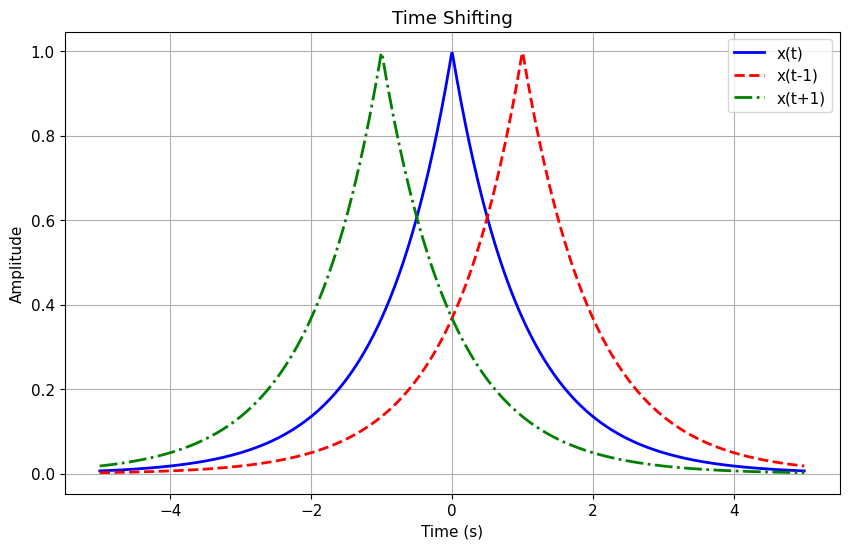

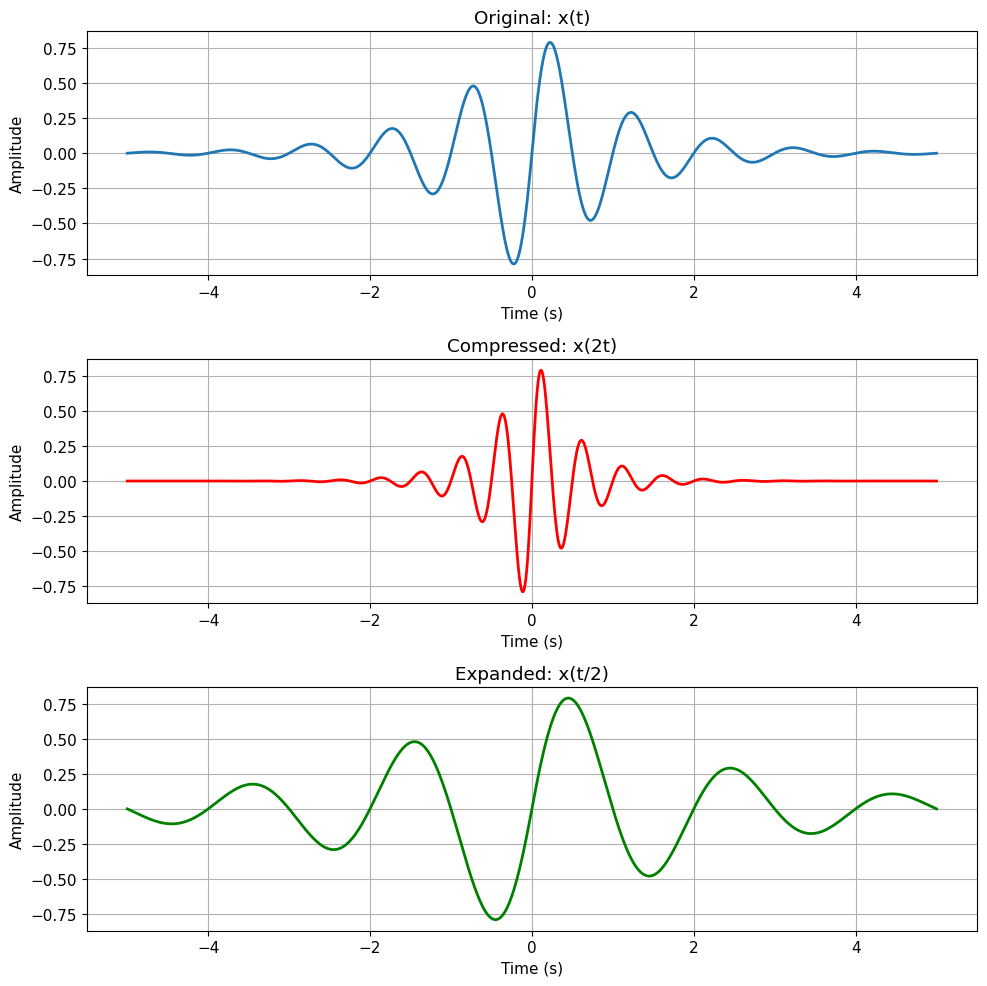

In [6]:
# Time Shifting (Delay)
t = np.linspace(-5, 5, 1000)
x = np.exp(-np.abs(t))

# Different time shifts
x_shift1 = np.exp(-np.abs(t-1))  # Shifted right by 1
x_shift2 = np.exp(-np.abs(t+1))  # Shifted left by 1

plt.figure()
plt.plot(t, x, 'b-', label='x(t)', linewidth=2)
plt.plot(t, x_shift1, 'r--', label='x(t-1)', linewidth=2)
plt.plot(t, x_shift2, 'g-.', label='x(t+1)', linewidth=2)
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.title('Time Shifting')
plt.legend()
plt.grid(True)
plt.show()

# Time Scaling (Compression and Expansion)
x = np.exp(-np.abs(t)) * np.sin(2*np.pi*t)

fig, axes = plt.subplots(3, 1, figsize=(10, 10))

axes[0].plot(t, x, linewidth=2)
axes[0].set_title('Original: x(t)')
axes[0].set_xlabel('Time (s)')
axes[0].set_ylabel('Amplitude')
axes[0].grid(True)

x_compressed = np.exp(-np.abs(2*t)) * np.sin(2*np.pi*2*t)
axes[1].plot(t, x_compressed, 'r', linewidth=2)
axes[1].set_title('Compressed: x(2t)')
axes[1].set_xlabel('Time (s)')
axes[1].set_ylabel('Amplitude')
axes[1].grid(True)

x_expanded = np.exp(-np.abs(0.5*t)) * np.sin(2*np.pi*0.5*t)
axes[2].plot(t, x_expanded, 'g', linewidth=2)
axes[2].set_title('Expanded: x(t/2)')
axes[2].set_xlabel('Time (s)')
axes[2].set_ylabel('Amplitude')
axes[2].grid(True)

plt.tight_layout()
plt.show()

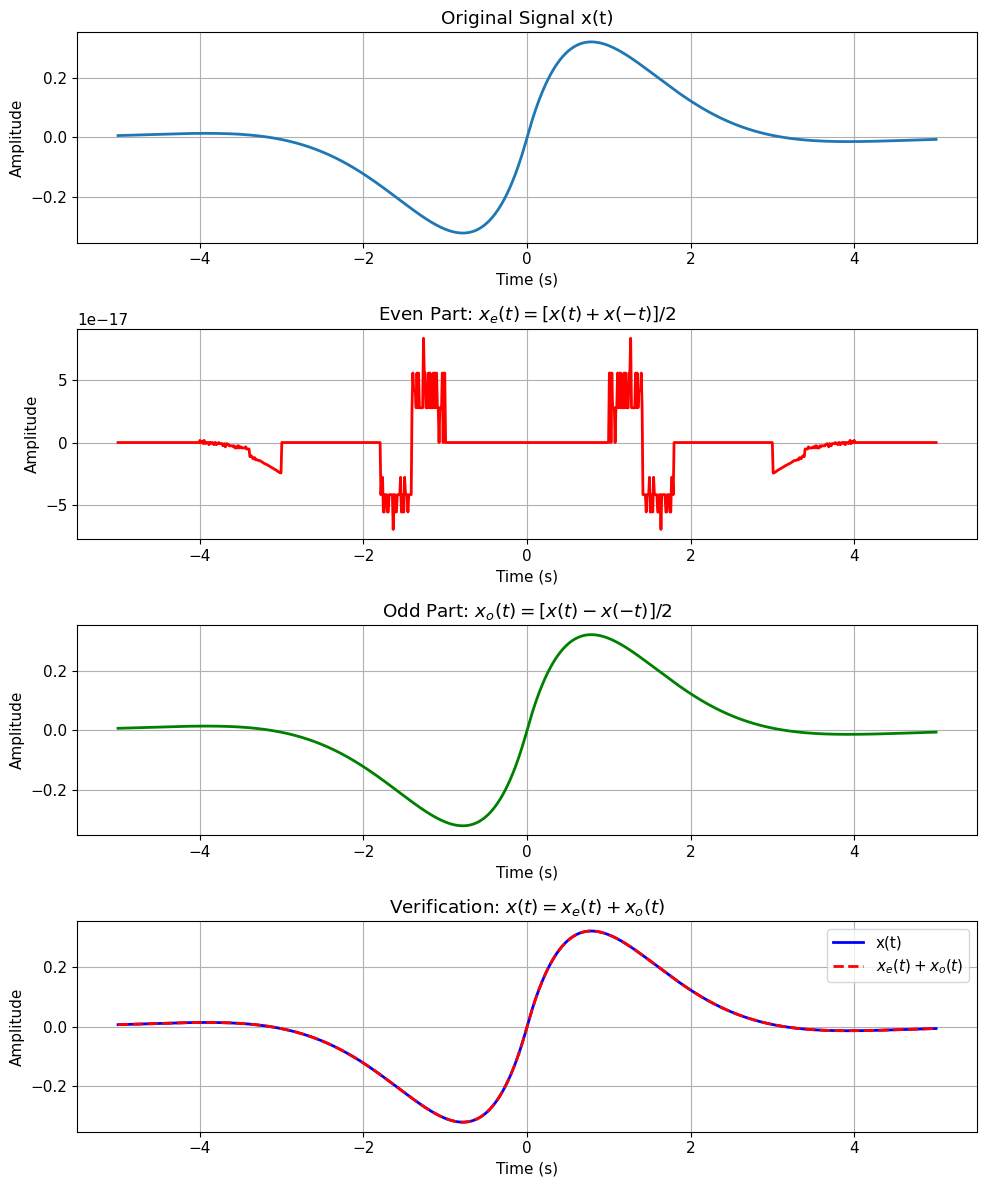

In [7]:
# Decompose signal into even and odd parts
t = np.linspace(-5, 5, 1000)
x = np.exp(-np.abs(t)) * np.sin(t)

# Create x(-t) by flipping
x_reversed = np.flip(x)

# Even and odd parts
x_even = (x + x_reversed) / 2
x_odd = (x - x_reversed) / 2

fig, axes = plt.subplots(4, 1, figsize=(10, 12))

axes[0].plot(t, x, linewidth=2)
axes[0].set_title('Original Signal x(t)')
axes[0].set_xlabel('Time (s)')
axes[0].set_ylabel('Amplitude')
axes[0].grid(True)

axes[1].plot(t, x_even, 'r', linewidth=2)
axes[1].set_title('Even Part: $x_e(t) = [x(t) + x(-t)]/2$')
axes[1].set_xlabel('Time (s)')
axes[1].set_ylabel('Amplitude')
axes[1].grid(True)

axes[2].plot(t, x_odd, 'g', linewidth=2)
axes[2].set_title('Odd Part: $x_o(t) = [x(t) - x(-t)]/2$')
axes[2].set_xlabel('Time (s)')
axes[2].set_ylabel('Amplitude')
axes[2].grid(True)

axes[3].plot(t, x, 'b-', label='x(t)', linewidth=2)
axes[3].plot(t, x_even + x_odd, 'r--', label='$x_e(t) + x_o(t)$', linewidth=2)
axes[3].set_title('Verification: $x(t) = x_e(t) + x_o(t)$')
axes[3].set_xlabel('Time (s)')
axes[3].set_ylabel('Amplitude')
axes[3].legend()
axes[3].grid(True)

plt.tight_layout()
plt.show()

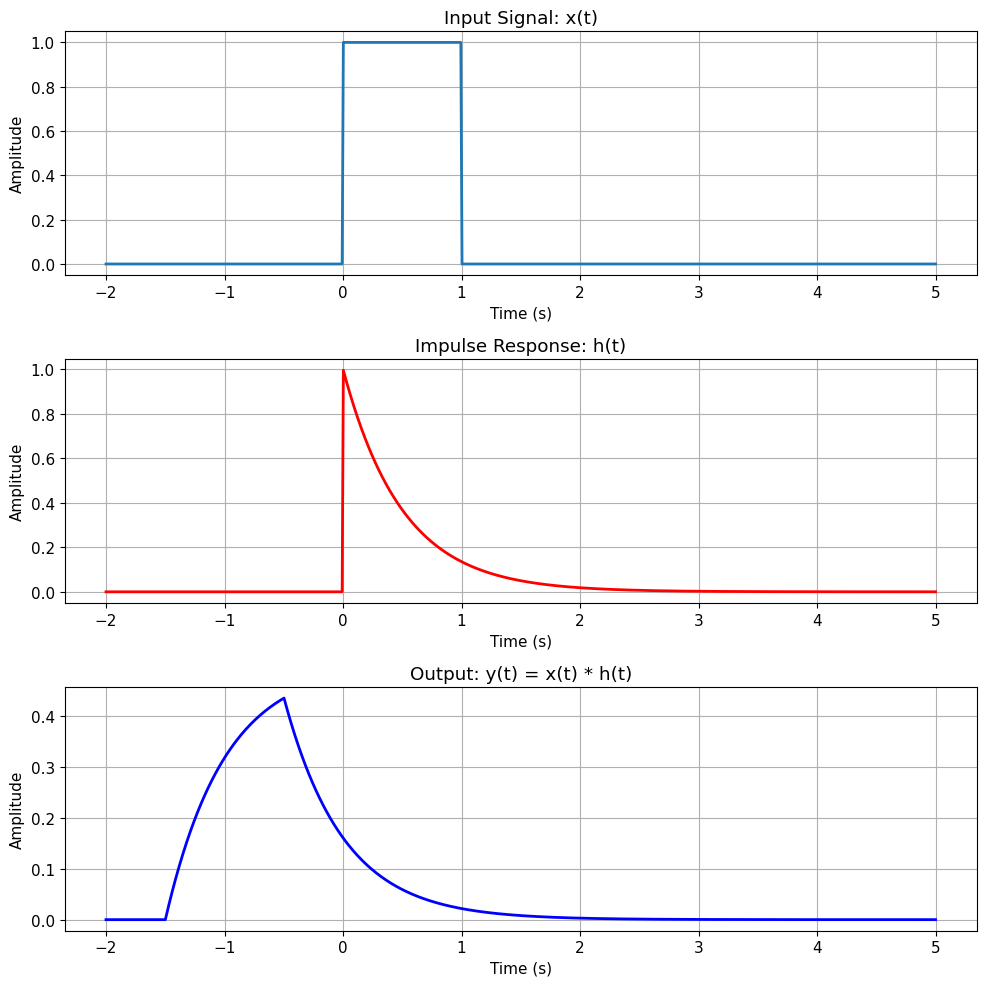

In [8]:
# Convolution: y(t) = x(t) * h(t)
from scipy.signal import convolve

# Define signals
t = np.linspace(-2, 5, 700)
dt = t[1] - t[0]
x = ((t >= 0) & (t <= 1)).astype(float)  # Rectangular pulse
h = np.exp(-2*t) * (t >= 0)              # Exponential

# Method 1: Using scipy.signal.convolve
y_conv = convolve(x, h, mode='same') * dt

# Plot results
fig, axes = plt.subplots(3, 1, figsize=(10, 10))

axes[0].plot(t, x, linewidth=2)
axes[0].set_title('Input Signal: x(t)')
axes[0].set_xlabel('Time (s)')
axes[0].set_ylabel('Amplitude')
axes[0].grid(True)

axes[1].plot(t, h, 'r', linewidth=2)
axes[1].set_title('Impulse Response: h(t)')
axes[1].set_xlabel('Time (s)')
axes[1].set_ylabel('Amplitude')
axes[1].grid(True)

axes[2].plot(t, y_conv, 'b', linewidth=2)
axes[2].set_title('Output: y(t) = x(t) * h(t)')
axes[2].set_xlabel('Time (s)')
axes[2].set_ylabel('Amplitude')
axes[2].grid(True)

plt.tight_layout()
plt.show()

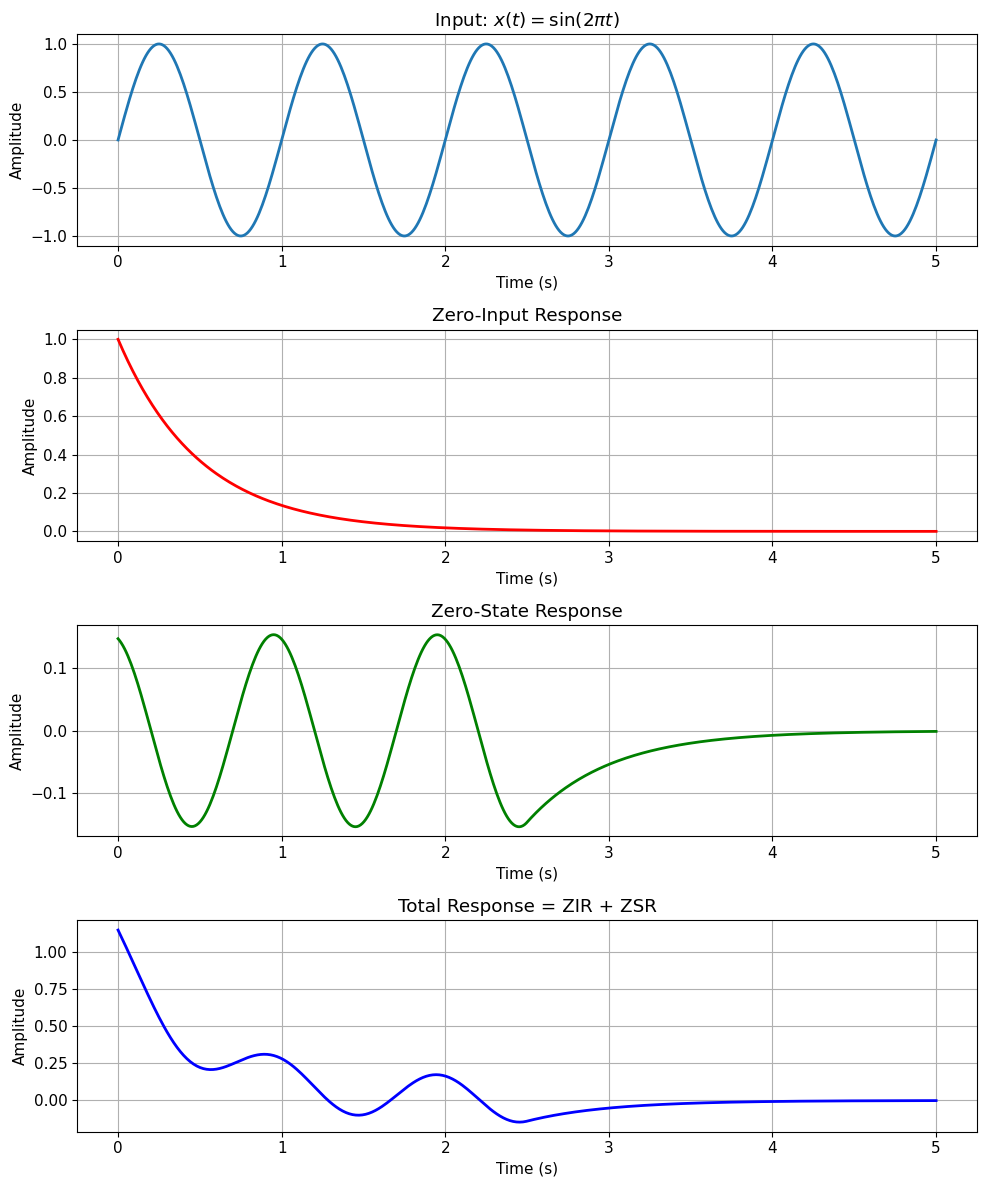

In [9]:
# Solving: dy/dt + ay = x(t)
a = 2  # System parameter
t = np.linspace(0, 5, 500)
dt = t[1] - t[0]

# Input signal
x = np.sin(2*np.pi*t)

# Initial condition
y0 = 1

# Zero-Input Response (x(t) = 0, y(0) = y0)
y_zi = y0 * np.exp(-a*t)

# Zero-State Response (y(0) = 0)
h = np.exp(-a*t)  # Impulse response
y_zs = convolve(x, h, mode='same') * dt

# Total Response
y_total = y_zi + y_zs

# Plot
fig, axes = plt.subplots(4, 1, figsize=(10, 12))

axes[0].plot(t, x, linewidth=2)
axes[0].set_title('Input: $x(t) = \\sin(2\\pi t)$')
axes[0].set_xlabel('Time (s)')
axes[0].set_ylabel('Amplitude')
axes[0].grid(True)

axes[1].plot(t, y_zi, 'r', linewidth=2)
axes[1].set_title('Zero-Input Response')
axes[1].set_xlabel('Time (s)')
axes[1].set_ylabel('Amplitude')
axes[1].grid(True)

axes[2].plot(t, y_zs, 'g', linewidth=2)
axes[2].set_title('Zero-State Response')
axes[2].set_xlabel('Time (s)')
axes[2].set_ylabel('Amplitude')
axes[2].grid(True)

axes[3].plot(t, y_total, 'b', linewidth=2)
axes[3].set_title('Total Response = ZIR + ZSR')
axes[3].set_xlabel('Time (s)')
axes[3].set_ylabel('Amplitude')
axes[3].grid(True)

plt.tight_layout()
plt.show()

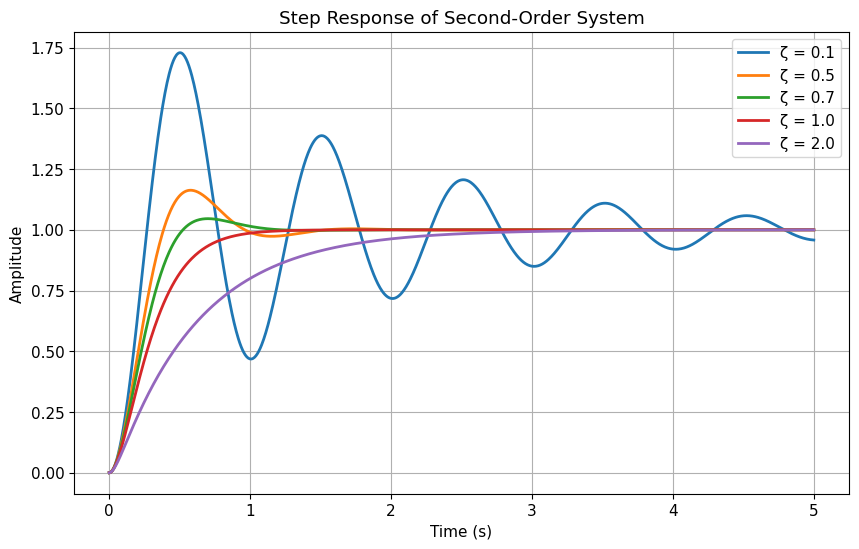

In [10]:
# Second-order system using scipy.signal
from scipy.signal import lti, step

wn = 2*np.pi  # Natural frequency
zeta_values = [0.1, 0.5, 0.7, 1.0, 2.0]  # Damping ratios

t = np.linspace(0, 5, 1000)

plt.figure(figsize=(10, 6))
for zeta in zeta_values:
    # Transfer function: H(s) = wn^2 / (s^2 + 2*zeta*wn*s + wn^2)
    num = [wn**2]
    den = [1, 2*zeta*wn, wn**2]
    system = lti(num, den)
    t_step, y = step(system, T=t)
    plt.plot(t_step, y, linewidth=2, label=f'ζ = {zeta}')

plt.title('Step Response of Second-Order System')
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.legend()
plt.grid(True)
plt.show()

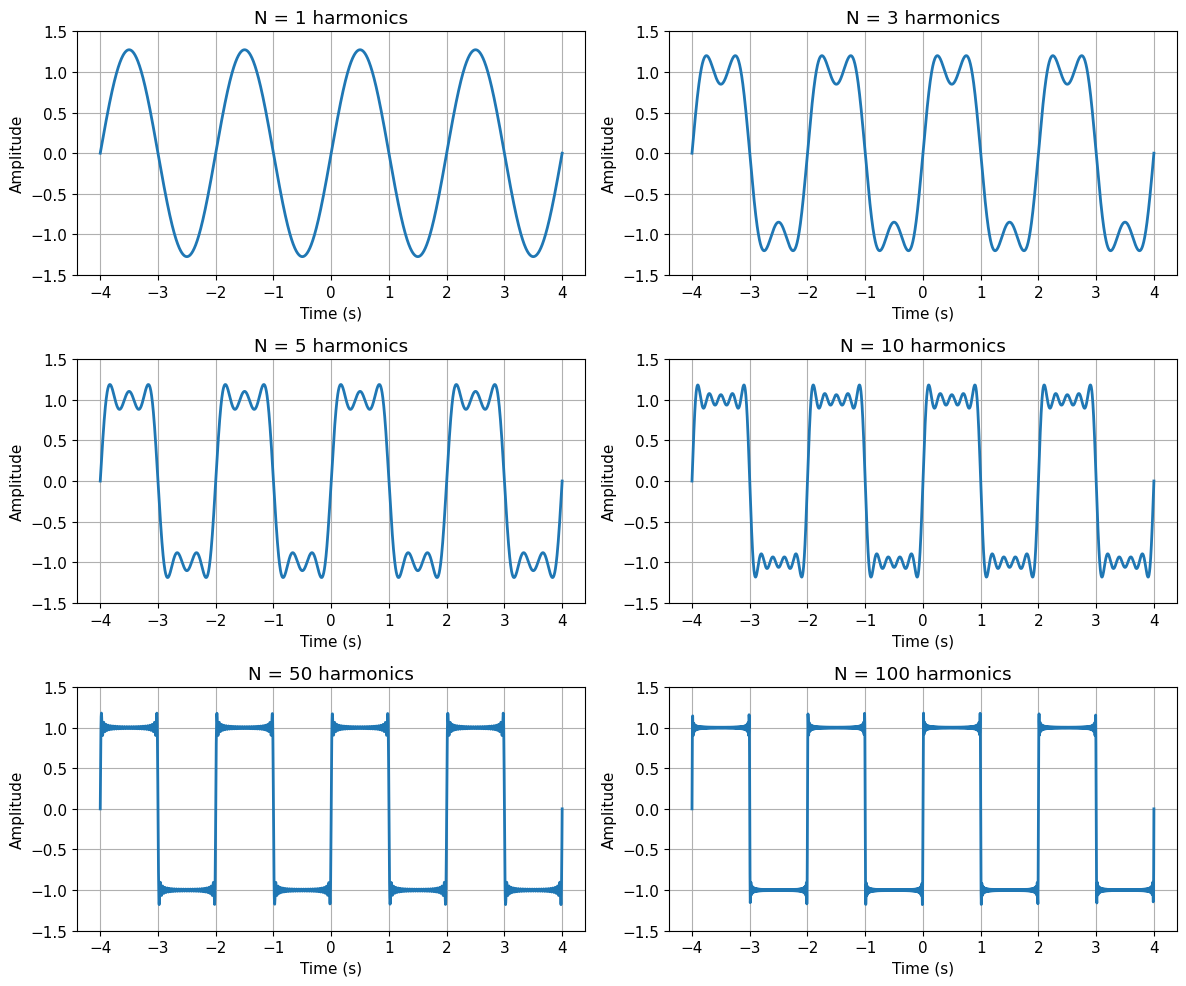

Notice Gibbs phenomenon at discontinuities!


In [11]:
# Fourier Series: x(t) = a0 + Σ[an*cos(nω0t) + bn*sin(nω0t)]
T = 2            # Period
f0 = 1/T         # Fundamental frequency
w0 = 2*np.pi*f0  # Angular frequency
t = np.linspace(-2*T, 2*T, 2000)

N_values = [1, 3, 5, 10, 50]
fig, axes = plt.subplots(3, 2, figsize=(12, 10))
axes = axes.flatten()

for idx, N in enumerate(N_values):
    x = np.zeros_like(t)
    
    # Fourier series for square wave (odd harmonics only)
    for n in range(1, N+1, 2):
        bn = 4/(n*np.pi)
        x += bn * np.sin(n*w0*t)
    
    axes[idx].plot(t, x, linewidth=2)
    axes[idx].set_ylim([-1.5, 1.5])
    axes[idx].set_title(f'N = {N} harmonics')
    axes[idx].set_xlabel('Time (s)')
    axes[idx].set_ylabel('Amplitude')
    axes[idx].grid(True)

# Last subplot with N=100
N = 100
x = np.zeros_like(t)
for n in range(1, N+1, 2):
    bn = 4/(n*np.pi)
    x += bn * np.sin(n*w0*t)
axes[5].plot(t, x, linewidth=2)
axes[5].set_ylim([-1.5, 1.5])
axes[5].set_title(f'N = {N} harmonics')
axes[5].set_xlabel('Time (s)')
axes[5].set_ylabel('Amplitude')
axes[5].grid(True)

plt.tight_layout()
plt.show()
print('Notice Gibbs phenomenon at discontinuities!')

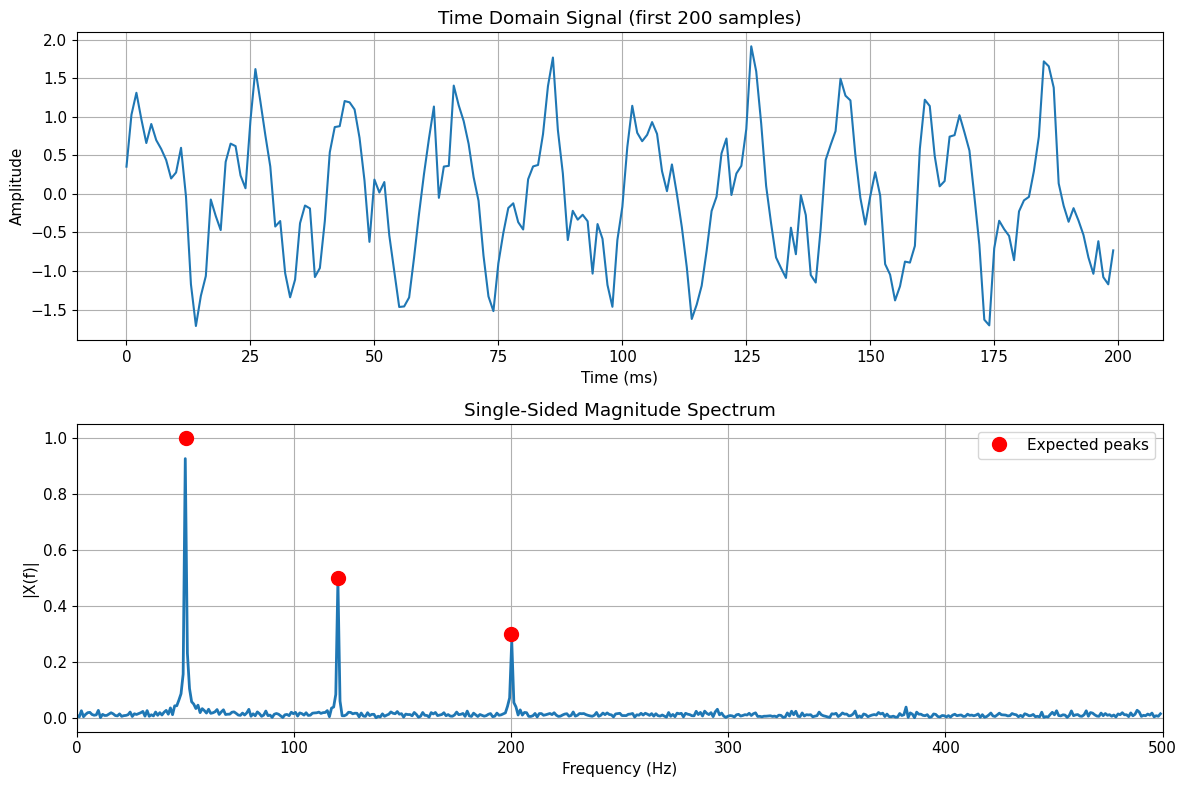

Detected frequencies: [ 49.8046875 120.1171875 200.1953125]


In [13]:
# FFT Example: Multi-component signal analysis
from scipy.fft import fft, fftfreq

Fs = 1000        # Sampling frequency (Hz)
T = 1/Fs         # Sampling period
N = 1024         # Length of signal
t = np.arange(N) * T

# Create signal with multiple frequencies
f1, f2, f3 = 50, 120, 200  # Hz
x = 1.0*np.sin(2*np.pi*f1*t) + 0.5*np.sin(2*np.pi*f2*t) + 0.3*np.sin(2*np.pi*f3*t)

# Add noise
x = x + 0.2*np.random.randn(N)

# Compute FFT
X = fft(x)
freqs = fftfreq(N, T)

# Single-sided spectrum
X_mag = np.abs(X/N)
X_mag[1:N//2] = 2 * X_mag[1:N//2]  # Double for single-sided
freqs_pos = freqs[:N//2]
X_mag_pos = X_mag[:N//2]

# Plot results
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8))

ax1.plot(t[:200]*1000, x[:200], linewidth=1.5)
ax1.set_title('Time Domain Signal (first 200 samples)')
ax1.set_xlabel('Time (ms)')
ax1.set_ylabel('Amplitude')
ax1.grid(True)

ax2.plot(freqs_pos, X_mag_pos, linewidth=2)
ax2.set_title('Single-Sided Magnitude Spectrum')
ax2.set_xlabel('Frequency (Hz)')
ax2.set_ylabel('|X(f)|')
ax2.set_xlim([0, Fs/2])
ax2.grid(True)
ax2.plot([f1, f2, f3], [1.0, 0.5, 0.3], 'ro', markersize=10, label='Expected peaks')
ax2.legend()

plt.tight_layout()
plt.show()

# Peak detection
from scipy.signal import find_peaks
peaks, _ = find_peaks(X_mag_pos, height=0.2)
detected_freqs = freqs_pos[peaks]
print('Detected frequencies:', detected_freqs)

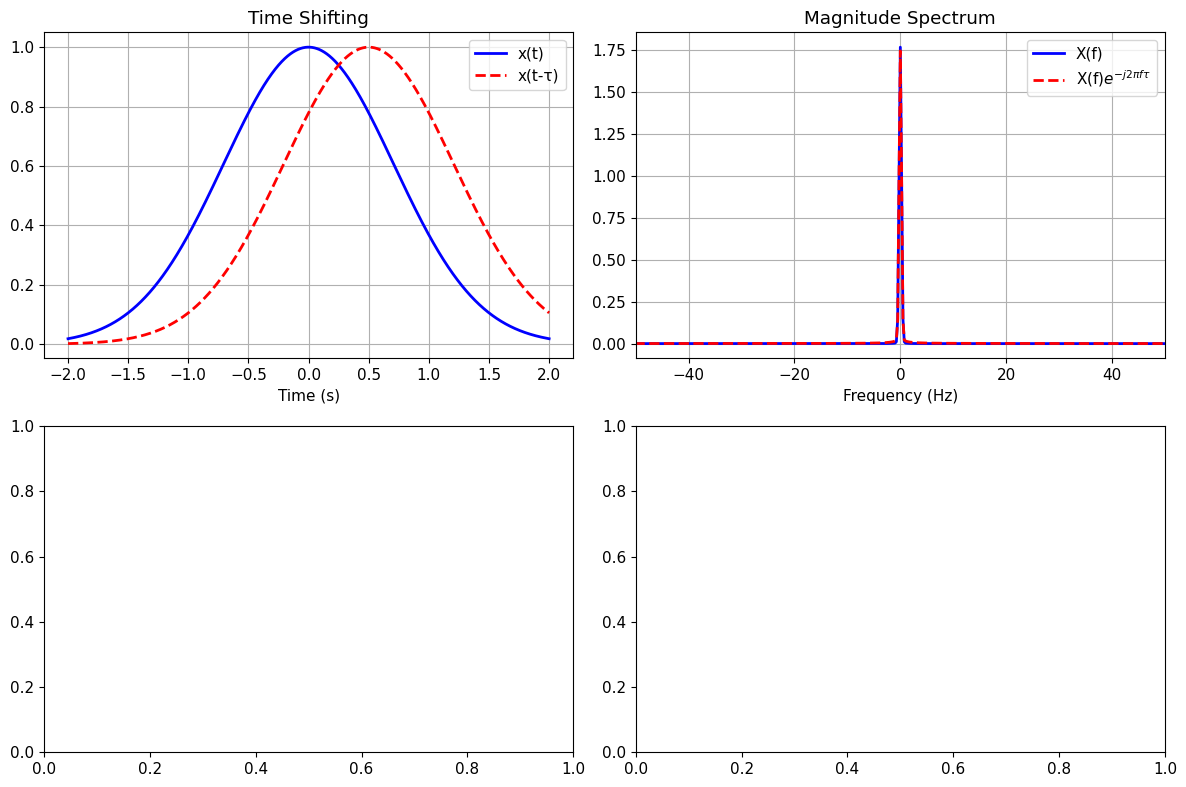

In [14]:
# Demonstrate Time Shifting Property
from scipy.fft import fft, fftshift, fftfreq

Fs = 1000
t = np.linspace(-2, 2, 4*Fs)
dt = t[1] - t[0]

# Original signal
x = np.exp(-t**2)

# Time shifted signal
tau = 0.5
x_shifted = np.exp(-(t-tau)**2)

# Compute FFTs
X = fftshift(fft(x)) * dt
X_shifted = fftshift(fft(x_shifted)) * dt
freqs = fftshift(fftfreq(len(t), dt))

# Plot
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

axes[0, 0].plot(t, x, 'b-', label='x(t)', linewidth=2)
axes[0, 0].plot(t, x_shifted, 'r--', label='x(t-τ)', linewidth=2)
axes[0, 0].set_title('Time Shifting')
axes[0, 0].set_xlabel('Time (s)')
axes[0, 0].legend()
axes[0, 0].grid(True)

axes[0, 1].plot(freqs, np.abs(X), 'b-', label='X(f)', linewidth=2)
axes[0, 1].plot(freqs, np.abs(X_shifted), 'r--', label='X(f)$e^{-j2πfτ}$', linewidth=2)
axes[0, 1].set_title('Magnitude Spectrum')
axes[0, 1].set_xlabel('Frequency (Hz)')
axes[0, 1].set_xlim([-50, 50])
axes[0, 1].legend()
axes[0, 1].grid(True)

plt.tight_layout()
plt.show()

Cutoff frequency fc = 159.15 Hz


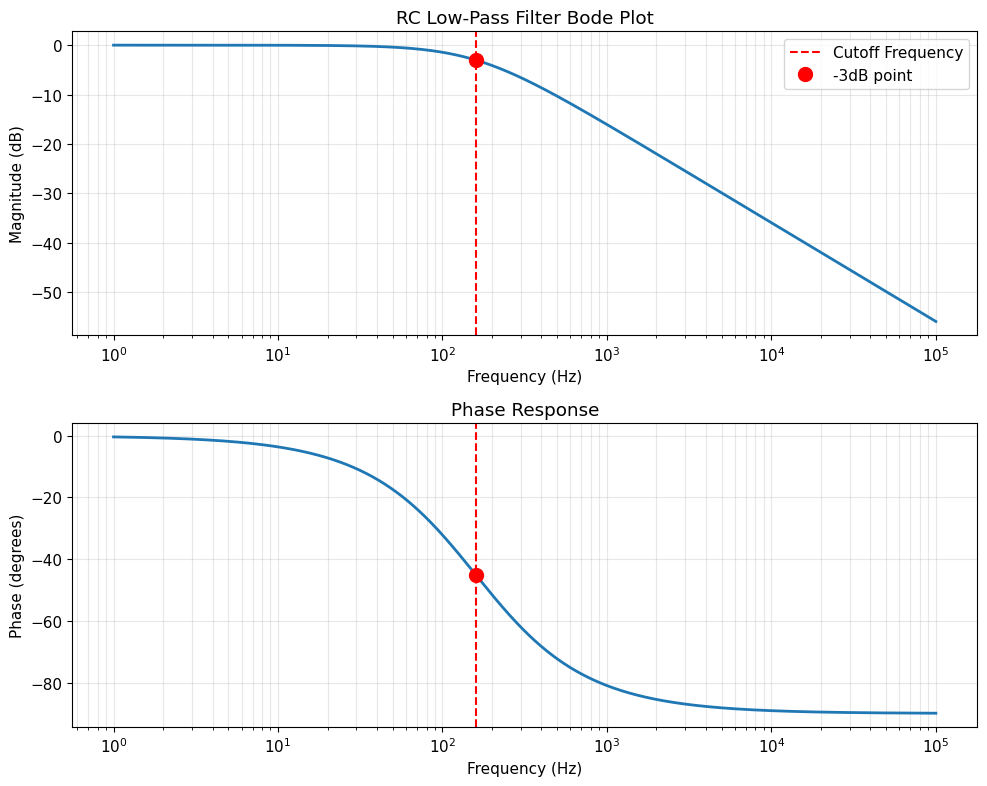

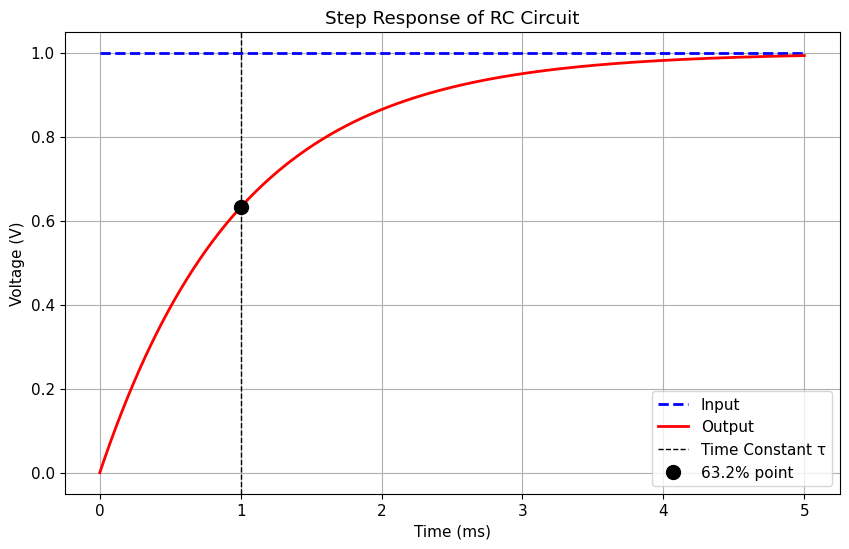

In [15]:
# RC Circuit: Low-pass filter
R = 1000      # Resistance (Ohms)
C = 1e-6      # Capacitance (Farads)
fc = 1/(2*np.pi*R*C)  # Cutoff frequency

print(f'Cutoff frequency fc = {fc:.2f} Hz')

# Frequency range
f = np.logspace(0, 5, 1000)  # 1 Hz to 100 kHz
w = 2*np.pi*f

# Frequency response
H = 1 / (1 + 1j*w*R*C)
mag = np.abs(H)
mag_dB = 20*np.log10(mag)
phase = np.angle(H) * 180/np.pi

# Plot Bode diagram
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8))

ax1.semilogx(f, mag_dB, linewidth=2)
ax1.grid(True, which='both', alpha=0.3)
ax1.set_xlabel('Frequency (Hz)')
ax1.set_ylabel('Magnitude (dB)')
ax1.set_title('RC Low-Pass Filter Bode Plot')
ax1.axvline(fc, color='r', linestyle='--', linewidth=1.5, label='Cutoff Frequency')
ax1.plot(fc, -3, 'ro', markersize=10, label='-3dB point')
ax1.legend()

ax2.semilogx(f, phase, linewidth=2)
ax2.grid(True, which='both', alpha=0.3)
ax2.set_xlabel('Frequency (Hz)')
ax2.set_ylabel('Phase (degrees)')
ax2.set_title('Phase Response')
ax2.axvline(fc, color='r', linestyle='--', linewidth=1.5)
ax2.plot(fc, -45, 'ro', markersize=10)

plt.tight_layout()
plt.show()

# Time domain step response
t = np.linspace(0, 0.005, 1000)
v_in = np.ones_like(t)
tau = R*C
v_out = 1 - np.exp(-t/tau)

plt.figure(figsize=(10, 6))
plt.plot(t*1000, v_in, 'b--', linewidth=2, label='Input')
plt.plot(t*1000, v_out, 'r-', linewidth=2, label='Output')
plt.axvline(tau*1000, color='k', linestyle='--', linewidth=1, label='Time Constant τ')
plt.plot(tau*1000, 1-np.exp(-1), 'ko', markersize=10, label='63.2% point')
plt.xlabel('Time (ms)')
plt.ylabel('Voltage (V)')
plt.title('Step Response of RC Circuit')
plt.legend()
plt.grid(True)
plt.show()

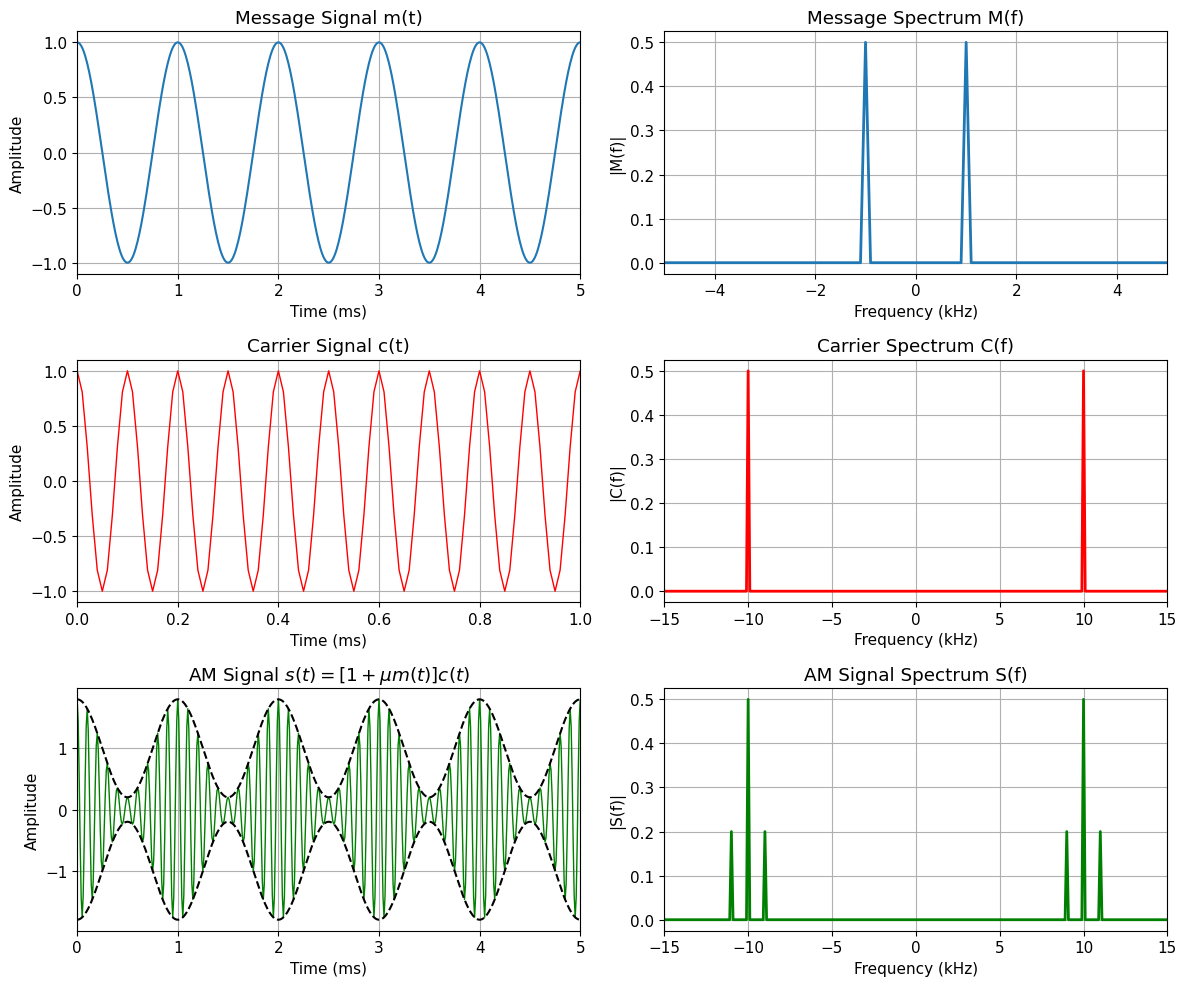

Modulation Index μ = 0.80
Bandwidth = 2fm = 2000.0 Hz


In [16]:
# Amplitude Modulation (AM)
fm = 1000    # Message frequency (1 kHz)
fc = 10000   # Carrier frequency (10 kHz)
fs = 100000  # Sampling frequency (100 kHz)
t = np.arange(0, 0.01, 1/fs)  # Time vector (10 ms)

# Message signal
m = np.cos(2*np.pi*fm*t)

# Carrier signal
c = np.cos(2*np.pi*fc*t)

# Modulation index
mu = 0.8

# AM signal
s_AM = (1 + mu*m) * c

# Frequency domain
N = len(s_AM)
f_axis = fftshift(fftfreq(N, 1/fs))
M = fftshift(fft(m))/N
C = fftshift(fft(c))/N
S = fftshift(fft(s_AM))/N

# Plot
fig = plt.figure(figsize=(12, 10))

# Time domain
ax1 = plt.subplot(3, 2, 1)
ax1.plot(t*1000, m, linewidth=1.5)
ax1.set_title('Message Signal m(t)')
ax1.set_xlabel('Time (ms)')
ax1.set_ylabel('Amplitude')
ax1.grid(True)
ax1.set_xlim([0, 5])

ax2 = plt.subplot(3, 2, 3)
ax2.plot(t*1000, c, 'r', linewidth=1)
ax2.set_title('Carrier Signal c(t)')
ax2.set_xlabel('Time (ms)')
ax2.set_ylabel('Amplitude')
ax2.grid(True)
ax2.set_xlim([0, 1])

ax3 = plt.subplot(3, 2, 5)
ax3.plot(t*1000, s_AM, 'g', linewidth=1)
envelope_upper = 1 + mu*m
envelope_lower = -(1 + mu*m)
ax3.plot(t*1000, envelope_upper, 'k--', linewidth=1.5)
ax3.plot(t*1000, envelope_lower, 'k--', linewidth=1.5)
ax3.set_title('AM Signal $s(t) = [1 + \\mu m(t)]c(t)$')
ax3.set_xlabel('Time (ms)')
ax3.set_ylabel('Amplitude')
ax3.grid(True)
ax3.set_xlim([0, 5])

# Frequency domain
ax4 = plt.subplot(3, 2, 2)
ax4.plot(f_axis/1000, np.abs(M), linewidth=2)
ax4.set_title('Message Spectrum M(f)')
ax4.set_xlabel('Frequency (kHz)')
ax4.set_ylabel('|M(f)|')
ax4.grid(True)
ax4.set_xlim([-5, 5])

ax5 = plt.subplot(3, 2, 4)
ax5.plot(f_axis/1000, np.abs(C), 'r', linewidth=2)
ax5.set_title('Carrier Spectrum C(f)')
ax5.set_xlabel('Frequency (kHz)')
ax5.set_ylabel('|C(f)|')
ax5.grid(True)
ax5.set_xlim([-15, 15])

ax6 = plt.subplot(3, 2, 6)
ax6.plot(f_axis/1000, np.abs(S), 'g', linewidth=2)
ax6.set_title('AM Signal Spectrum S(f)')
ax6.set_xlabel('Frequency (kHz)')
ax6.set_ylabel('|S(f)|')
ax6.grid(True)
ax6.set_xlim([-15, 15])

plt.tight_layout()
plt.show()

print(f'Modulation Index μ = {mu:.2f}')
print(f'Bandwidth = 2fm = {2*fm:.1f} Hz')

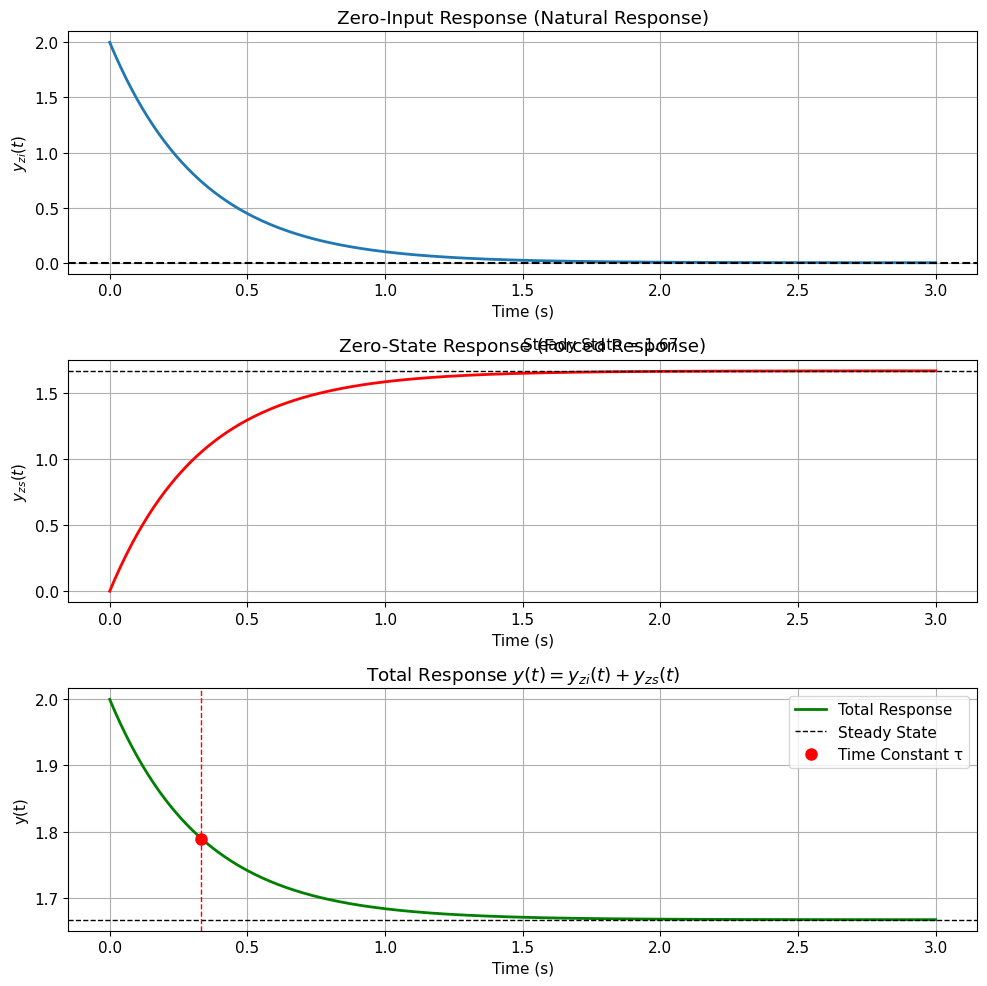

Time Constant τ = 0.333 s
Steady-State y(∞) = 1.667
95% settling time ≈ 3τ = 1.000 s


In [17]:
# First-order system: dy/dt + ay = bx(t)
# Given: dy/dt + 3y = 5u(t), y(0) = 2

a = 3
b = 5
y0 = 2
t = np.linspace(0, 3, 300)

# Analytical Solution
y_zi = y0 * np.exp(-a*t)           # Zero-input response
y_zs = (b/a) * (1 - np.exp(-a*t))  # Zero-state response
y_total = y_zi + y_zs

# System parameters
y_ss = b/a   # Steady-state
tau = 1/a    # Time constant

# Plot
fig, axes = plt.subplots(3, 1, figsize=(10, 10))

axes[0].plot(t, y_zi, linewidth=2)
axes[0].set_title('Zero-Input Response (Natural Response)')
axes[0].set_xlabel('Time (s)')
axes[0].set_ylabel('$y_{zi}(t)$')
axes[0].axhline(0, color='k', linestyle='--')
axes[0].grid(True)

axes[1].plot(t, y_zs, 'r', linewidth=2)
axes[1].axhline(y_ss, color='k', linestyle='--', linewidth=1)
axes[1].text(1.5, y_ss*1.1, f'Steady State = {y_ss:.2f}')
axes[1].set_title('Zero-State Response (Forced Response)')
axes[1].set_xlabel('Time (s)')
axes[1].set_ylabel('$y_{zs}(t)$')
axes[1].grid(True)

axes[2].plot(t, y_total, 'g', linewidth=2, label='Total Response')
axes[2].axhline(y_ss, color='k', linestyle='--', linewidth=1, label='Steady State')
axes[2].axvline(tau, color='r', linestyle='--', linewidth=1)
y_at_tau = y0*np.exp(-1) + y_ss*(1-np.exp(-1))
axes[2].plot(tau, y_at_tau, 'ro', markersize=8, label='Time Constant τ')
axes[2].set_title('Total Response $y(t) = y_{zi}(t) + y_{zs}(t)$')
axes[2].set_xlabel('Time (s)')
axes[2].set_ylabel('y(t)')
axes[2].legend()
axes[2].grid(True)

plt.tight_layout()
plt.show()

print(f'Time Constant τ = {tau:.3f} s')
print(f'Steady-State y(∞) = {y_ss:.3f}')
print(f'95% settling time ≈ 3τ = {3*tau:.3f} s')

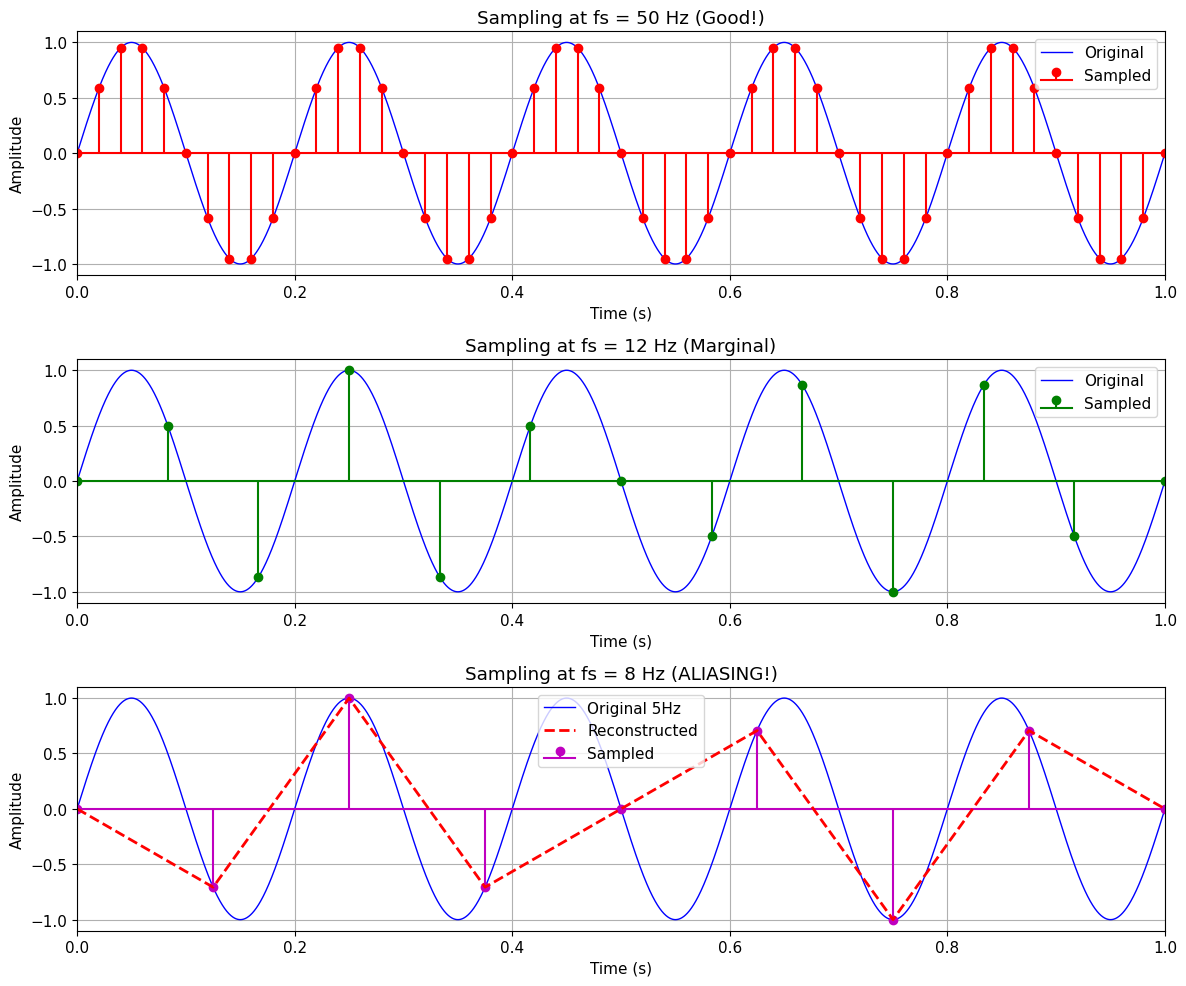

Nyquist Theorem: fs > 2*f_max
For f_max = 5 Hz: fs > 10 Hz required


In [18]:
# Sampling and Aliasing Demonstration
f_signal = 5  # Signal frequency (Hz)
t_continuous = np.linspace(0, 2, 20000)
x_continuous = np.sin(2*np.pi*f_signal*t_continuous)

# Different sampling frequencies
fs1 = 50   # Well above Nyquist
fs2 = 12   # Just above Nyquist
fs3 = 8    # Below Nyquist - aliasing!

t1 = np.arange(0, 2, 1/fs1)
x1 = np.sin(2*np.pi*f_signal*t1)

t2 = np.arange(0, 2, 1/fs2)
x2 = np.sin(2*np.pi*f_signal*t2)

t3 = np.arange(0, 2, 1/fs3)
x3 = np.sin(2*np.pi*f_signal*t3)

# Plot
fig, axes = plt.subplots(3, 1, figsize=(12, 10))

axes[0].plot(t_continuous, x_continuous, 'b-', linewidth=1, label='Original')
axes[0].stem(t1, x1, linefmt='r-', markerfmt='ro', basefmt='r-', label='Sampled')
axes[0].set_title(f'Sampling at fs = {fs1} Hz (Good!)')
axes[0].set_xlabel('Time (s)')
axes[0].set_ylabel('Amplitude')
axes[0].legend()
axes[0].grid(True)
axes[0].set_xlim([0, 1])

axes[1].plot(t_continuous, x_continuous, 'b-', linewidth=1, label='Original')
axes[1].stem(t2, x2, linefmt='g-', markerfmt='go', basefmt='g-', label='Sampled')
axes[1].set_title(f'Sampling at fs = {fs2} Hz (Marginal)')
axes[1].set_xlabel('Time (s)')
axes[1].set_ylabel('Amplitude')
axes[1].legend()
axes[1].grid(True)
axes[1].set_xlim([0, 1])

axes[2].plot(t_continuous, x_continuous, 'b-', linewidth=1, label='Original 5Hz')
axes[2].stem(t3, x3, linefmt='m-', markerfmt='mo', basefmt='m-', label='Sampled')
x3_interp = np.interp(t_continuous, t3, x3)
axes[2].plot(t_continuous, x3_interp, 'r--', linewidth=2, label='Reconstructed')
axes[2].set_title(f'Sampling at fs = {fs3} Hz (ALIASING!)')
axes[2].set_xlabel('Time (s)')
axes[2].set_ylabel('Amplitude')
axes[2].legend()
axes[2].grid(True)
axes[2].set_xlim([0, 1])

plt.tight_layout()
plt.show()

print('Nyquist Theorem: fs > 2*f_max')
print('For f_max = 5 Hz: fs > 10 Hz required')